# **1. Introduction**
The research project focuses on machine learning-based prediction of student academic performance, with particular emphasis on feature importance and visual analytics. The main objective was not only to predict the Global Score, but also to understand which factors contribute most to the prediction and communicate these findings through an interactive dashboard.

# **2. Import libraries**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# data manipulation
import pandas as pd
import numpy as np

# data preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# EDA Visualization
import matplotlib.pyplot as plt
import seaborn as sns
#Machine Learning
from sklearn.model_selection import train_test_split

#Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Evaluation metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

#SHAP expainability
import shap


#**3. Load dataset**

In [ ]:
df=pd.read_excel("/content/data_academic_performance.xlsx")

# **4. Data Preparation**

In [ ]:
print("Dataset loaded successfully")
print("SHAPE:",df.shape)
df.head()

Dataset loaded successfully
SHAPE: (12411, 45)


,COD_S11,GENDER,EDU_FATHER,EDU_MOTHER,OCC_FATHER,OCC_MOTHER,STRATUM,SISBEN,PEOPLE_HOUSE,Unnamed: 9,...,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
0,SB11201210000129,F,Incomplete Professional Education,Complete technique or technology,Technical or professional level employee,Home,Stratum 4,It is not classified by the SISBEN,Three,NaN,...,71,93,79,181,180,91,5,4,2,2
1,SB11201210000137,F,Complete Secundary,Complete professional education,Entrepreneur,Independent professional,Stratum 5,It is not classified by the SISBEN,Three,NaN,...,86,98,78,201,182,92,5,4,4,4
2,SB11201210005154,M,Not sure,Not sure,Independent,Home,Stratum 2,Level 2,Five,NaN,...,18,43,22,113,113,7,1,1,1,1
3,SB11201210007504,F,Not sure,Not sure,Other occupation,Independent,Stratum 2,It is not classified by the SISBEN,Three,NaN,...,76,80,48,137,157,67,4,3,2,2
4,SB11201210007548,M,Complete professional education,Complete professional education,Executive,Home,Stratum 4,It is not classified by the SISBEN,One,NaN,...,98,100,71,189,198,98,5,4,4,2


In [ ]:
df.dtypes

,0
COD_S11,object
GENDER,object
EDU_FATHER,object
EDU_MOTHER,object
OCC_FATHER,object
OCC_MOTHER,object
STRATUM,object
SISBEN,object
PEOPLE_HOUSE,object
Unnamed: 9,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12411 entries, 0 to 12410
Data columns (total 45 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COD_S11           12411 non-null  object 
 1   GENDER            12411 non-null  object 
 2   EDU_FATHER        12411 non-null  object 
 3   EDU_MOTHER        12411 non-null  object 
 4   OCC_FATHER        12411 non-null  object 
 5   OCC_MOTHER        12411 non-null  object 
 6   STRATUM           12411 non-null  object 
 7   SISBEN            12411 non-null  object 
 8   PEOPLE_HOUSE      12411 non-null  object 
 9   Unnamed: 9        0 non-null      float64
 10  INTERNET          12411 non-null  object 
 11  TV                12411 non-null  object 
 12  COMPUTER          12411 non-null  object 
 13  WASHING_MCH       12411 non-null  object 
 14  MIC_OVEN          12411 non-null  object 
 15  CAR               12411 non-null  object 
 16  DVD               12411 non-null  object

In [ ]:
df.describe()

,Unnamed: 9,MAT_S11,CR_S11,CC_S11,BIO_S11,ENG_S11,QR_PRO,CR_PRO,CC_PRO,ENG_PRO,WC_PRO,FEP_PRO,G_SC,PERCENTILE,2ND_DECILE,QUARTILE,SEL,SEL_IHE
count,0.0,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.00000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000,12411.000000
mean,NaN,64.320764,60.778422,60.705181,63.950528,61.801064,77.417291,62.199339,59.18677,67.498348,53.703408,145.476593,162.710499,68.446459,3.885747,3.188865,2.598904,2.409395
std,NaN,11.873650,10.025876,10.120524,11.156869,14.297777,22.673444,27.666558,28.99184,25.495096,30.001734,40.126386,23.112479,25.867550,1.248431,0.979043,1.111704,0.926765
min,NaN,26.000000,24.000000,0.000000,11.000000,26.000000,1.000000,1.000000,1.00000,1.000000,0.000000,1.000000,37.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,NaN,56.000000,54.000000,54.000000,56.000000,50.000000,65.000000,42.000000,36.00000,51.000000,28.000000,124.000000,147.000000,51.000000,3.000000,3.000000,2.000000,2.000000
50%,NaN,64.000000,61.000000,60.000000,64.000000,59.000000,85.000000,67.000000,65.00000,74.000000,56.000000,153.000000,163.000000,75.000000,4.000000,4.000000,2.000000,2.000000
75%,NaN,72.000000,67.000000,67.000000,71.000000,72.000000,96.000000,86.000000,85.00000,88.000000,80.000000,174.000000,179.000000,90.000000,5.000000,4.000000,4.000000,3.000000
max,NaN,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,300.000000,247.000000,100.000000,5.000000,4.000000,4.000000,4.000000


## **Check for missing values and empty values**

In [ ]:
nan_count = df.isnull().sum()
zero_count = (df == 0).sum()
empty_string_count = (df == '').sum()

missing_values = pd.DataFrame({
    'NaN Count': nan_count,
    'Zero Count': zero_count,
    'Empty String Count': empty_string_count
})

print(missing_values)

                  NaN Count  Zero Count  Empty String Count
COD_S11                   0           0                   0
GENDER                    0           0                   0
EDU_FATHER                0         391                   0
EDU_MOTHER                0         388                   0
OCC_FATHER                0         940                   0
OCC_MOTHER                0         313                   0
STRATUM                   0          14                   0
SISBEN                    0          21                   0
PEOPLE_HOUSE              0          21                   0
Unnamed: 9            12411           0                   0
INTERNET                  0           0                   0
TV                        0           0                   0
COMPUTER                  0           0                   0
WASHING_MCH               0           0                   0
MIC_OVEN                  0           0                   0
CAR                       0           0 

## **Delete the meaningless empty column**

In [ ]:
del df['Unnamed: 9']

##**Check duplicate values**

In [ ]:
duplicate_count=df.duplicated().sum()
print("Duplicate count:", duplicate_count)
if duplicate_count> 0:
  df.drop_duplicates(inplace=True)
  print("Duplicate rows removed; New Shape", df.shape())
else:
  print("No duplicates found. Dataset is already unique")

Duplicate count: 0
No duplicates found. Dataset is already unique


##**Identify Numerical and categorical columns**

In [ ]:
numerical_columns = df.select_dtypes(include=['number']).columns
print("Numerical Columns:", list(numerical_columns))

Numerical Columns: ['MAT_S11', 'CR_S11', 'CC_S11', 'BIO_S11', 'ENG_S11', 'QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO', 'FEP_PRO', 'G_SC', 'PERCENTILE', '2ND_DECILE', 'QUARTILE', 'SEL', 'SEL_IHE']


In [ ]:
for categorical_column in df.select_dtypes(include=['object', 'category']).columns:
  print(f"{categorical_column}: {df[categorical_column].nunique()}")

COD_S11: 12411
GENDER: 2
EDU_FATHER: 12
EDU_MOTHER: 12
OCC_FATHER: 12
OCC_MOTHER: 12
STRATUM: 7
SISBEN: 6
PEOPLE_HOUSE: 13
INTERNET: 2
TV: 2
COMPUTER: 2
WASHING_MCH: 2
MIC_OVEN: 2
CAR: 2
DVD: 2
FRESH: 2
PHONE: 2
MOBILE: 2
REVENUE: 8
JOB: 4
SCHOOL_NAME: 3735
SCHOOL_NAT: 2
SCHOOL_TYPE: 4
Cod_SPro: 12395
UNIVERSITY: 134
ACADEMIC_PROGRAM: 21


#**5. Exploratory Data Analysis and feature engineering**

##**Outlier detection using IQR method**


In [ ]:
def detect_outliers_iqr(data, columns):
    results = []

    for c in columns:
        Q1 = data[c].quantile(0.25)
        Q3 = data[c].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - (1.5 * IQR)
        upper_bound = Q3 + (1.5 * IQR)

        outliers = data[(data[c] < lower_bound) | (data[c] > upper_bound)]
        outlier_count = len(outliers)

        outlier_percentage = outlier_count/len(data)*100
        results.append([c, outlier_count,round(outlier_percentage,2),round(lower_bound,2),round(upper_bound,2)])
    return pd.DataFrame(
        results,
        columns=[
            'Variable',
            'Outlier_Count',
            'Outlier_Percentage',
            'Lower_Bound',
            'Upper_Bound'
        ]
    )

numerical_variables =numerical_columns
outlier_details = detect_outliers_iqr(df, numerical_variables)
outlier_details


,Variable,Outlier_Count,Outlier_Percentage,Lower_Bound,Upper_Bound
0,MAT_S11,137,1.10,32.0,96.0
1,CR_S11,196,1.58,34.5,86.5
2,CC_S11,207,1.67,34.5,86.5
3,BIO_S11,166,1.34,33.5,93.5
4,ENG_S11,0,0.00,17.0,105.0
5,QR_PRO,290,2.34,18.5,142.5
6,CR_PRO,0,0.00,-24.0,152.0
7,CC_PRO,0,0.00,-37.5,158.5
8,ENG_PRO,0,0.00,-4.5,143.5
9,WC_PRO,0,0.00,-50.0,158.0


##**Boxplot plot for Outlier detection**

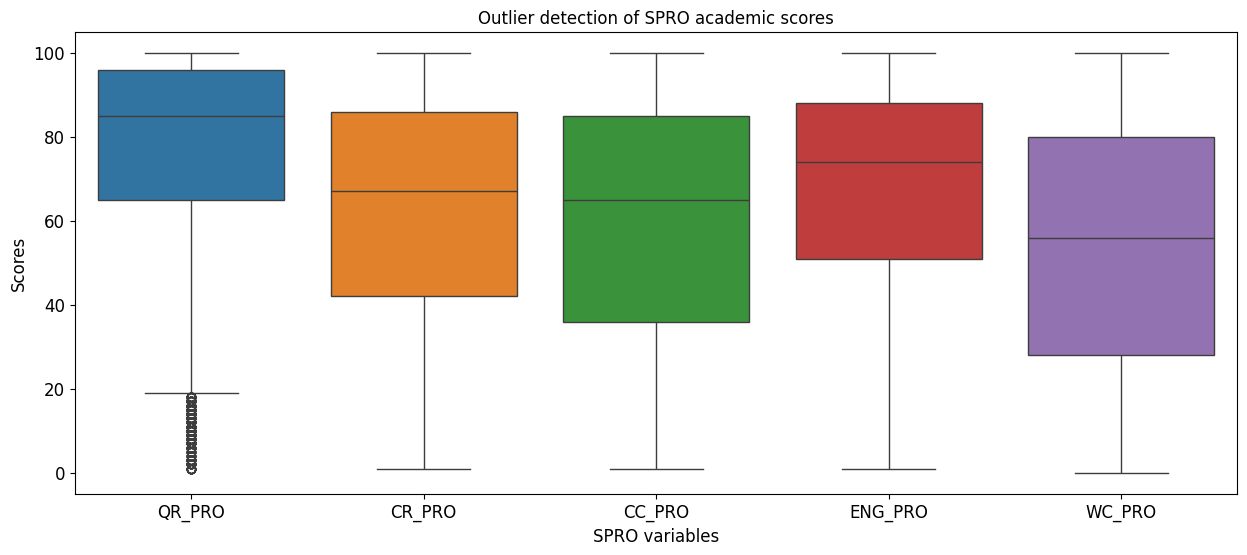

In [ ]:
plt.figure(figsize=(15,6))
spro_columns=['QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO']
sns.boxplot(data=df[spro_columns])
plt.title('Outlier detection of SPRO academic scores',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.xlabel('SPRO variables',fontsize=12,fontstyle='normal')
plt.ylabel('Scores',fontsize=12,fontstyle='normal')
plt.show()

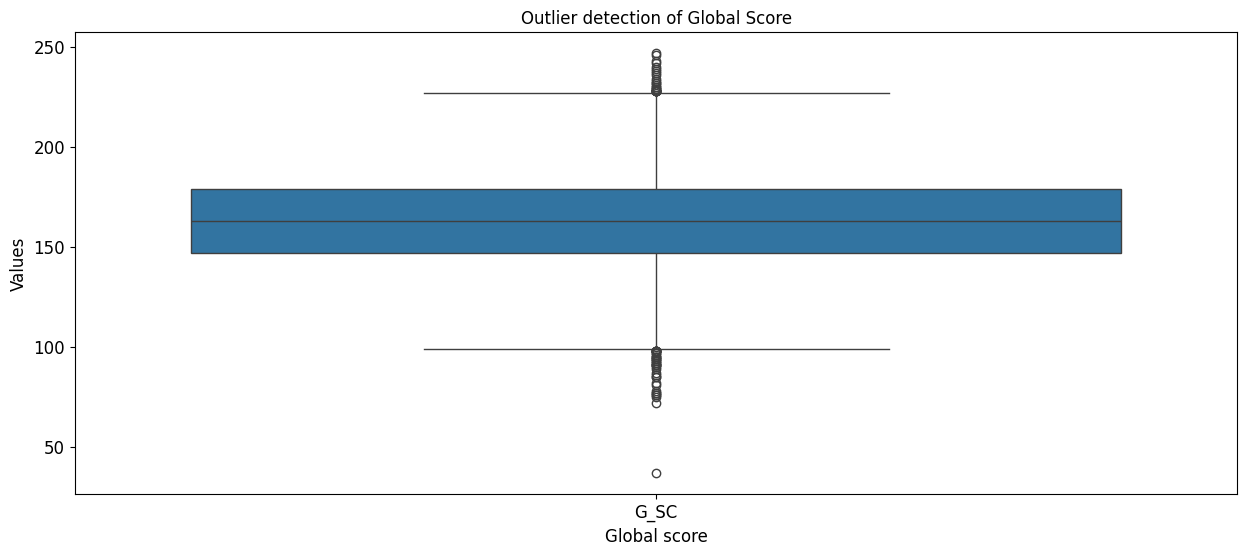

In [ ]:
plt.figure(figsize=(15,6))
sel_columns=['G_SC']
sns.boxplot(data=df[sel_columns])
plt.title('Outlier detection of Global Score',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.xlabel('Global score',fontsize=12,fontstyle='normal')
plt.ylabel('Values',fontsize=12,fontstyle='normal')
plt.show()

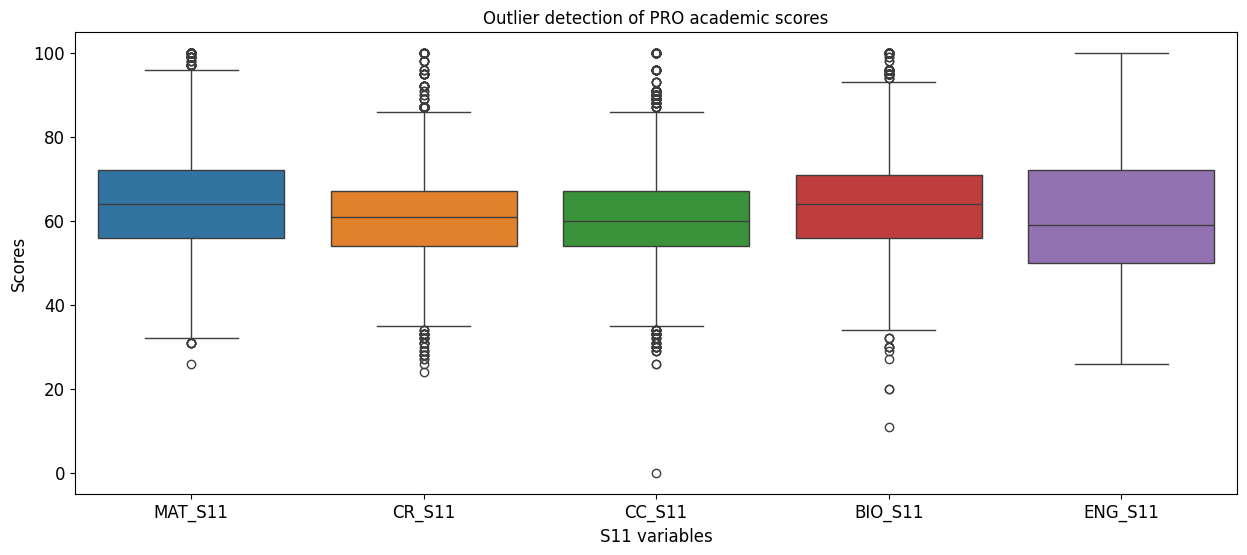

In [ ]:
plt.figure(figsize=(15,6))
s11_columns=['MAT_S11', 'CR_S11', 'CC_S11', 'BIO_S11', 'ENG_S11']
sns.boxplot(data=df[s11_columns])
plt.title('Outlier detection of PRO academic scores',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.xlabel('S11 variables',fontsize=12,fontstyle='normal')
plt.ylabel('Scores',fontsize=12,fontstyle='normal')
plt.show()

##**Outlier Percentage using Lollipop chart**

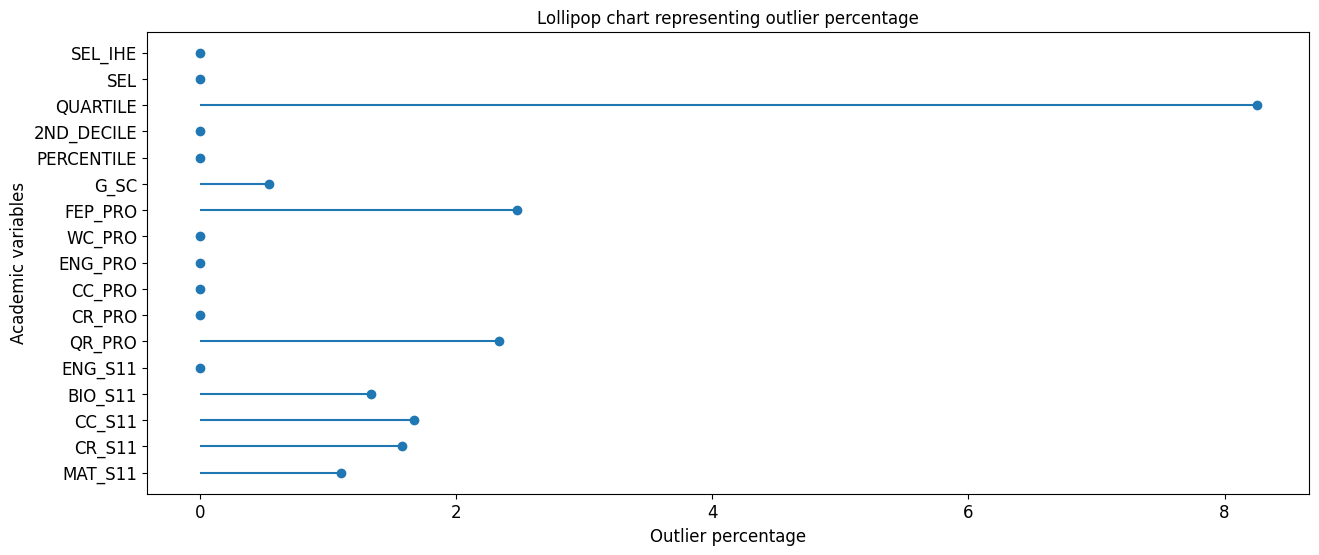

In [ ]:
plt.figure(figsize=(15,6))
plt.hlines(y=outlier_details['Variable'],xmin=0,xmax=outlier_details['Outlier_Percentage'])
plt.plot(outlier_details['Outlier_Percentage'],outlier_details['Variable'],'o')
plt.title('Lollipop chart representing outlier percentage',fontsize=12,fontstyle='normal')
plt.xlabel('Outlier percentage',fontsize=12,fontstyle='normal')
plt.ylabel('Academic variables',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()

##**Correlation matrix among numerical features**

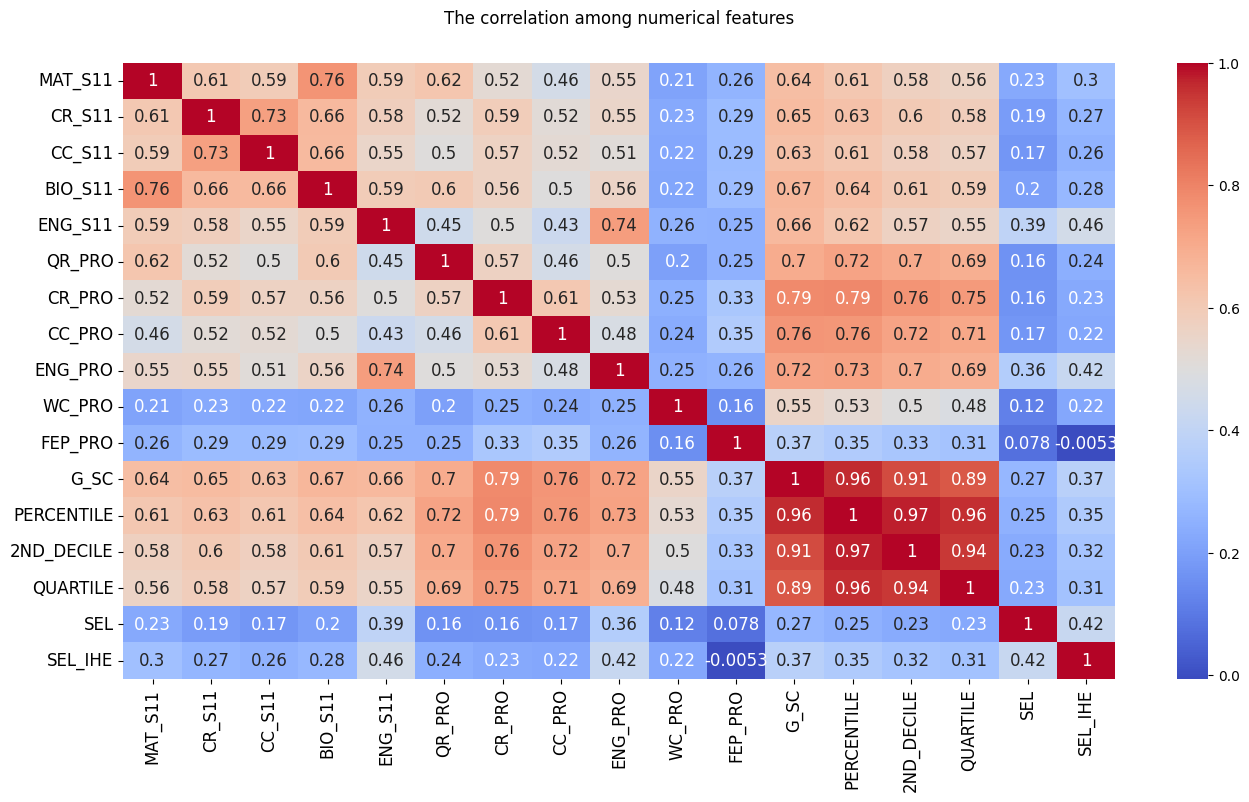

In [ ]:
plt.figure(figsize=(16, 8))
sns.heatmap(df[numerical_columns].corr(), annot = True, cmap = "coolwarm",annot_kws={"size":12})
plt.title('The correlation among numerical features',y= 1.05,fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()

## Distribution plots of numerical variables


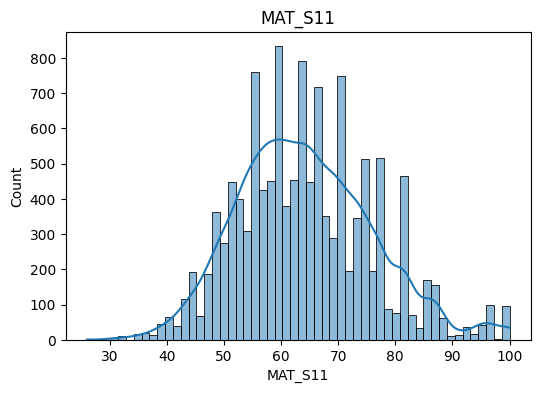

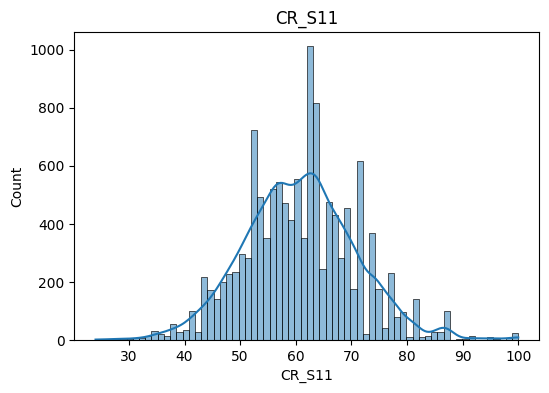

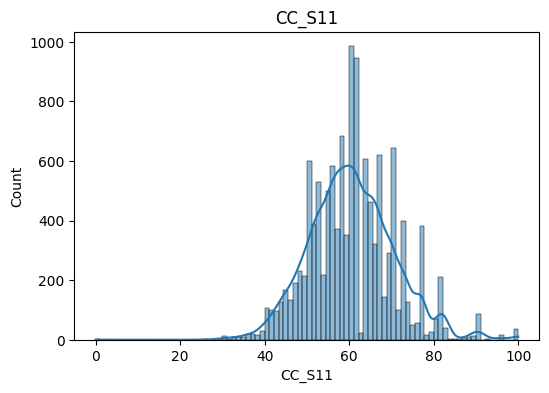

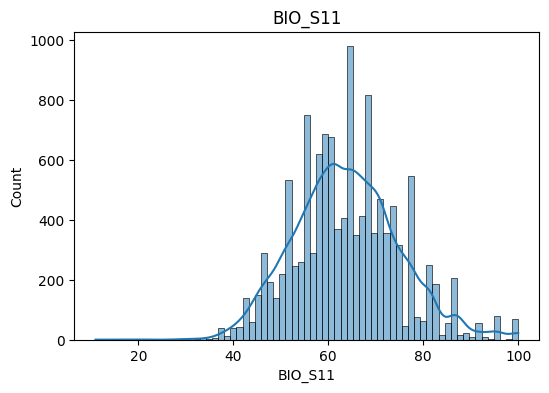

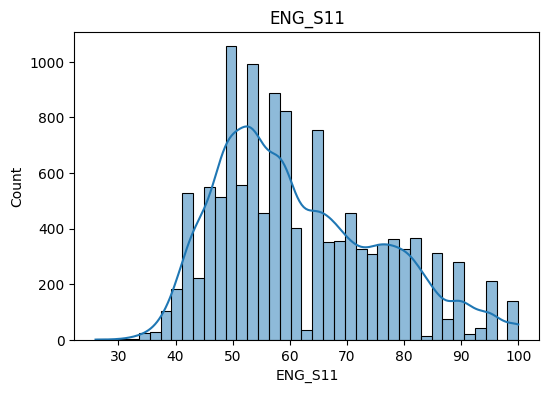

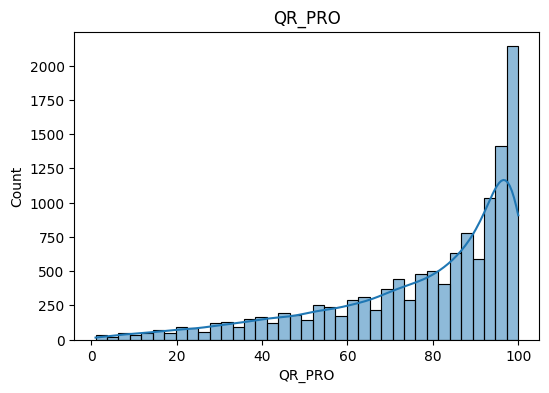

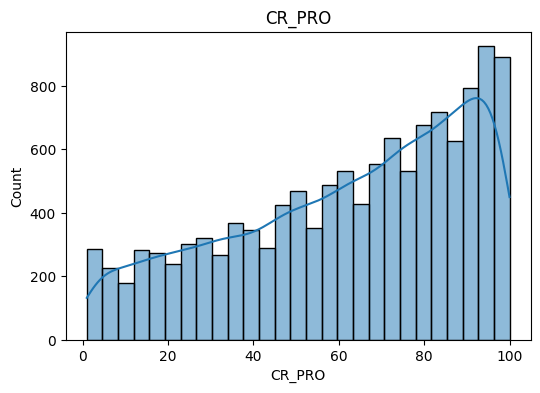

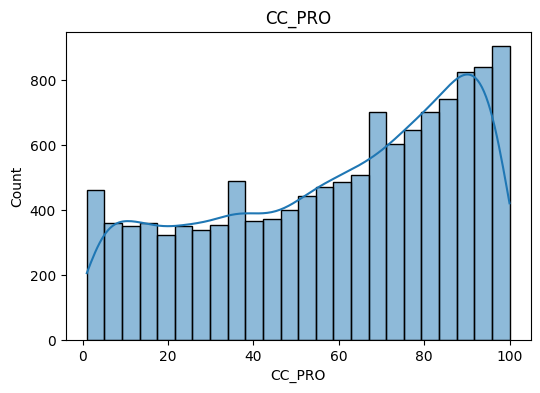

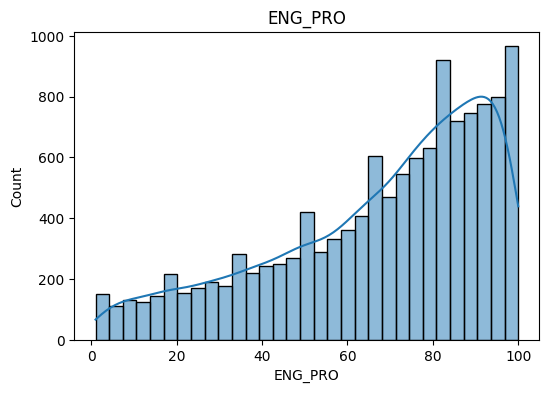

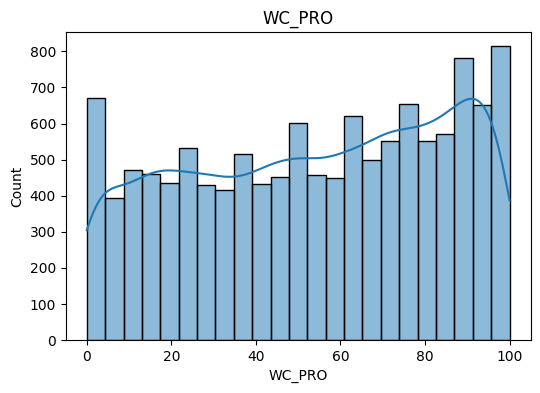

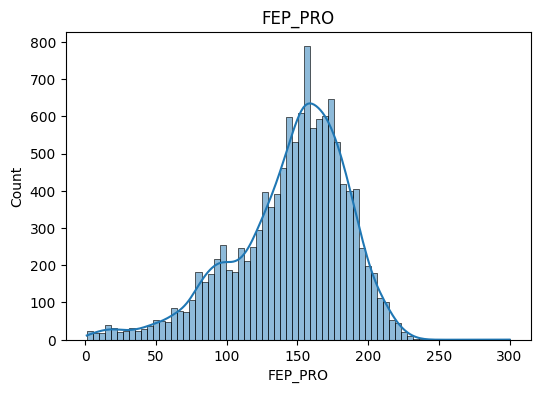

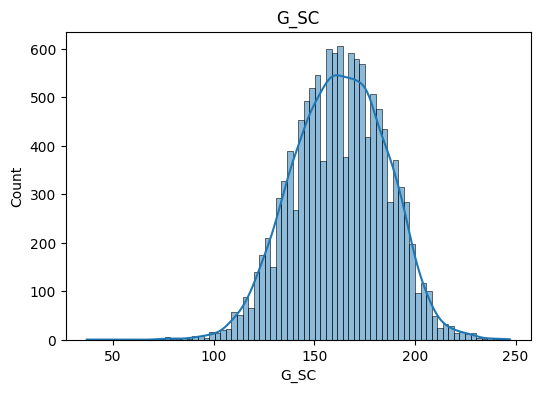

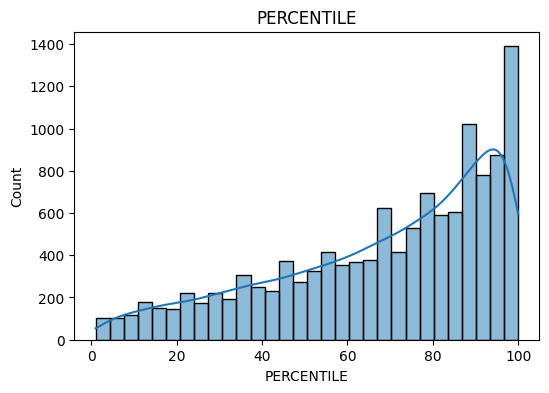

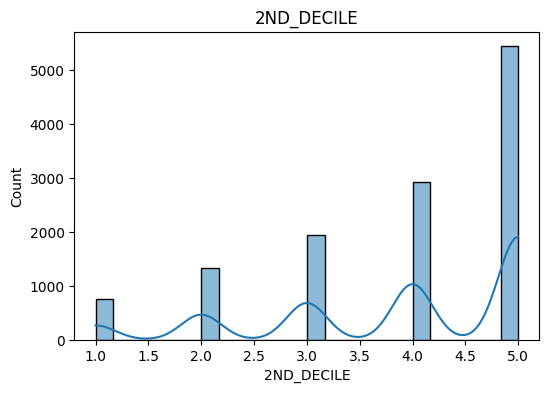

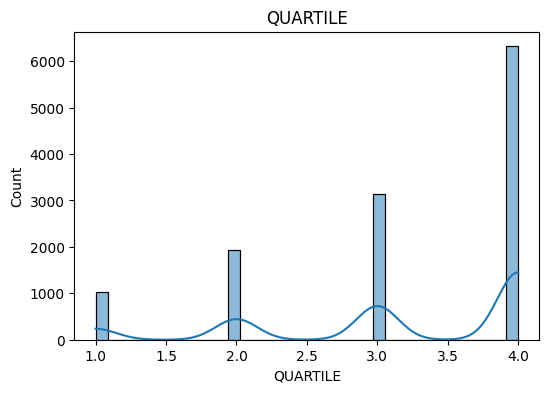

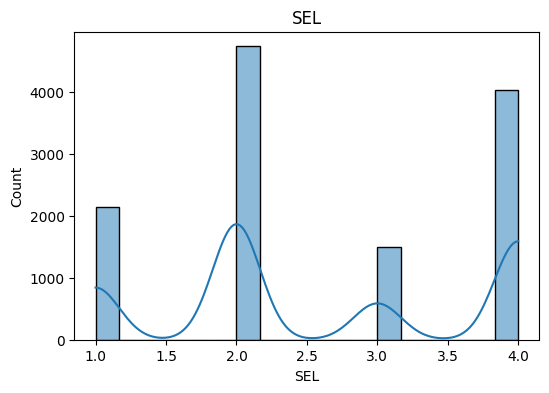

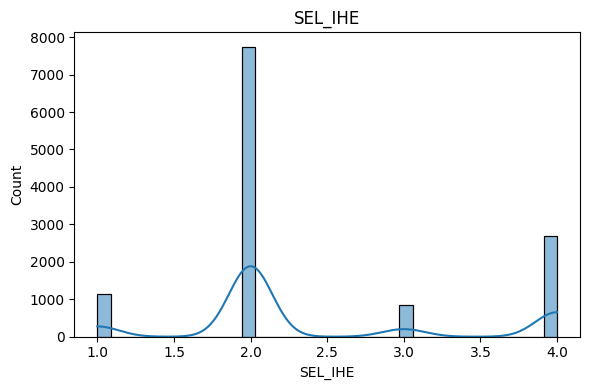

In [ ]:
for cols in numerical_columns:
  plt.figure(figsize=(6,4))
  sns.histplot(df[cols],kde=True)
  plt.title(cols)
plt.tight_layout()
plt.show()



##**Distribution of male and female.**

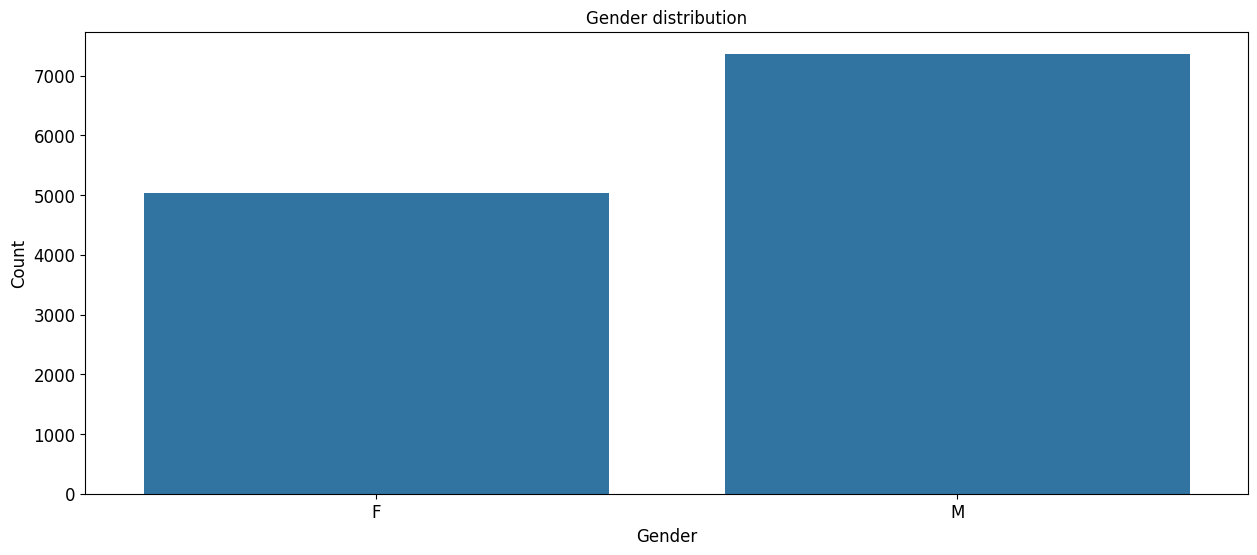

In [ ]:
plt.figure(figsize=(15,6))
sns.countplot(x='GENDER', data=df)
plt.title('Gender distribution',fontsize=12,fontstyle='normal')
plt.xlabel('Gender',fontsize=12,fontstyle='normal')
plt.ylabel('Count',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()



##**How does academic performance distributed between male and female?**

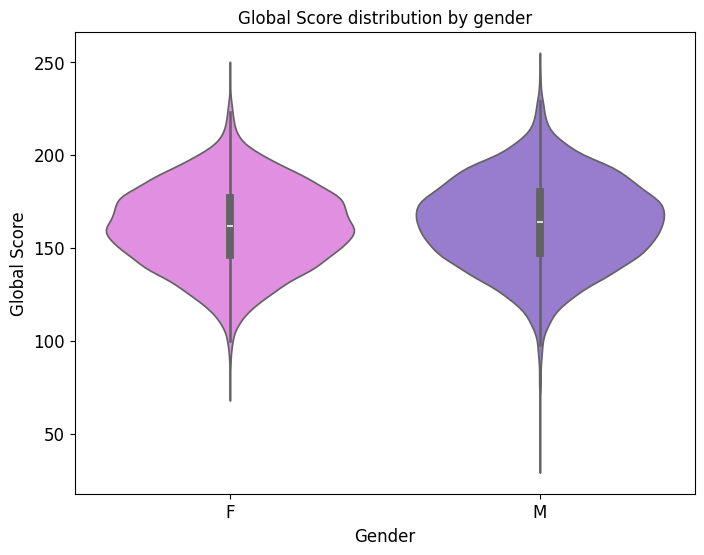

In [ ]:
plt.figure(figsize=(8,6))
sns.violinplot(data=df,x='GENDER',y ='G_SC',palette=['violet','mediumpurple'])
plt.title('Global Score distribution by gender',fontsize=12,fontstyle='normal')
plt.xlabel('Gender',fontsize=12,fontstyle='normal')
plt.ylabel('Global Score',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()

##**Top 10 Universities by Average Academic Performance**

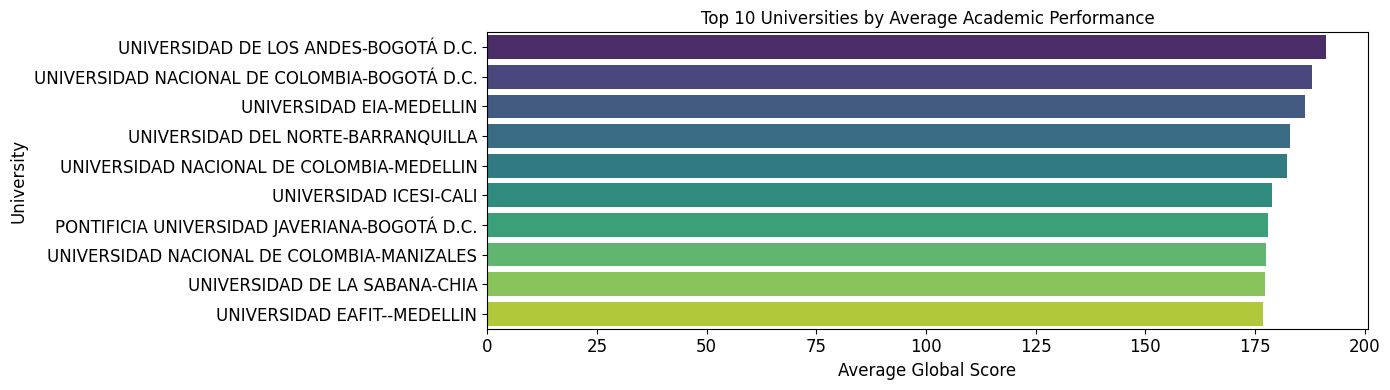

In [ ]:
top_10_universities=(df.groupby('UNIVERSITY')['G_SC'].mean().sort_values(ascending=False).head(10))
plt.figure(figsize=(14,4))
colors=sns.color_palette("viridis",n_colors=10)
sns.barplot(x=top_10_universities.values,y=top_10_universities.index,hue=top_10_universities.index,palette=colors,legend=False)
plt.title('Top 10 Universities by Average Academic Performance', fontsize=12)
plt.xlabel('Average Global Score',fontsize=12,fontstyle='normal')
plt.ylabel('University',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.tight_layout()
plt.show()

##**Distribution of global score over socioeconomic strata to find which strata exhibit best performance**


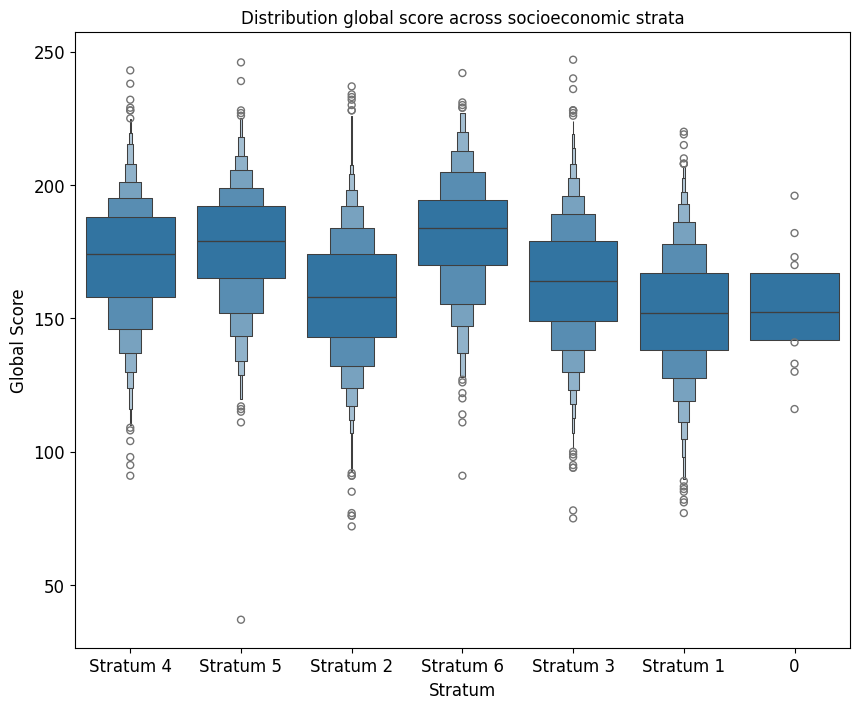

In [ ]:
plt.figure(figsize=(10,8))
sns.boxenplot(x='STRATUM',y='G_SC',data=df)
plt.title('Distribution global score across socioeconomic strata',fontsize=12,fontstyle='normal')
plt.xlabel('Stratum',fontsize=12,fontstyle='normal')
plt.ylabel('Global Score',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()

##**Distribution of students global score across SISBEN levels**

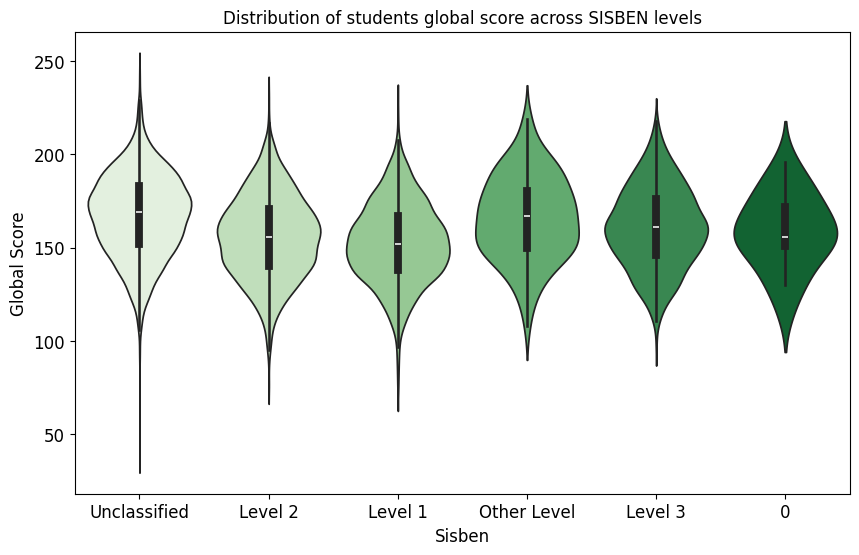

In [ ]:
#print(df['SISBEN'].value_counts().index.tolist())
plt.figure(figsize=(10,6))
rename_x= {'It is not classified by the SISBEN':'Unclassified', 'Esta clasificada en otro Level del SISBEN':'Other Level'}
df_plot=df.copy()
df_plot['SISBEN']=df_plot['SISBEN'].replace(rename_x)
sns.violinplot(x='SISBEN',y='G_SC', data=df_plot, palette ='Greens')
plt.title("Distribution of students global score across SISBEN levels",fontsize=12,fontstyle='normal')
plt.xlabel('Sisben',fontsize=12,fontstyle='normal')
plt.ylabel('Global Score',fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()

##**Distribution of global score across socioeconomic revenue**

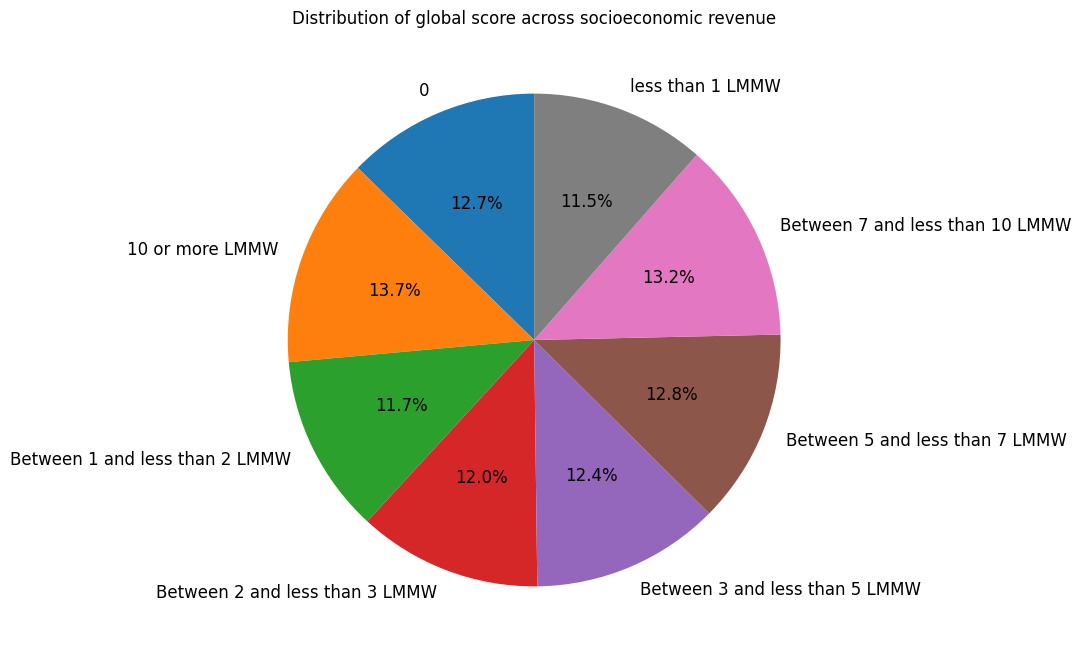

In [ ]:
r_count= df.groupby('REVENUE')['G_SC'].mean()
plt.figure(figsize=(8,8))
r_count.plot.pie(autopct='%1.1f%%',startangle =90,textprops={'fontsize':12})
plt.title('Distribution of global score across socioeconomic revenue',fontsize=12,fontstyle='normal')
plt.ylabel('')
plt.show()

##**Correlation Network Graph to find which academic variables are strongly interconnected.**

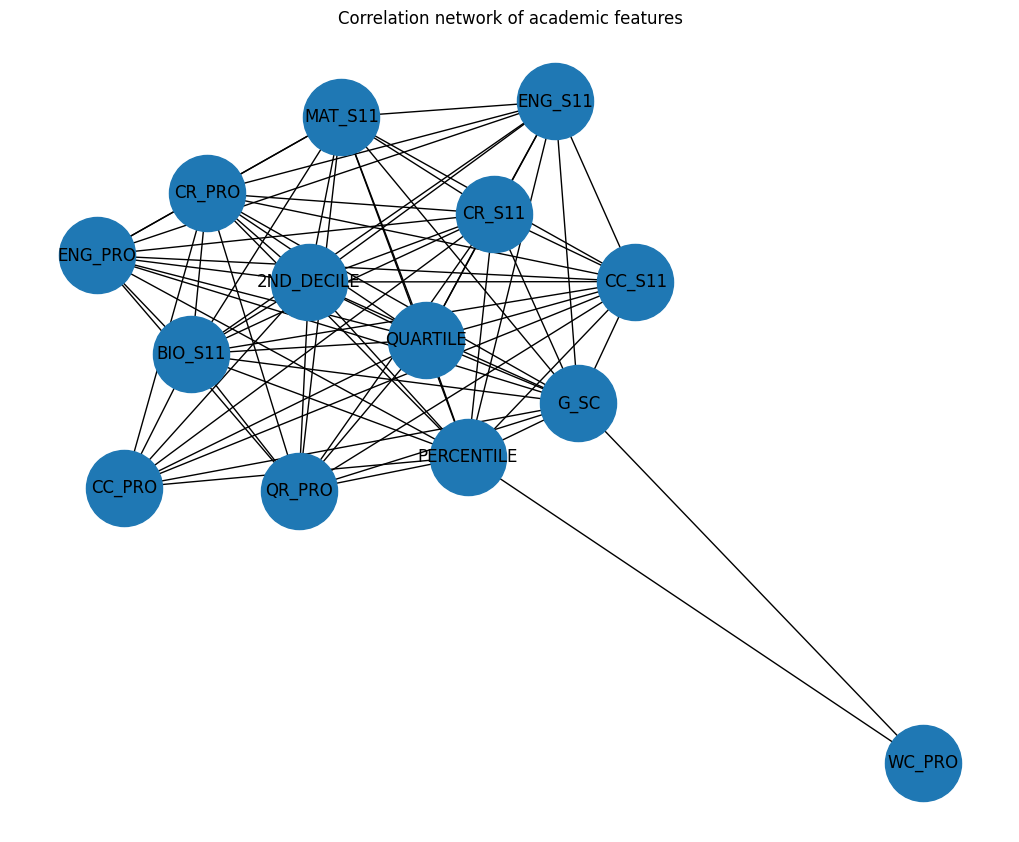

In [ ]:
import networkx as nx
corr_matrix=df[numerical_variables].corr()
gr=nx.Graph()
for i in corr_matrix.columns:
    for j in corr_matrix.columns:
        if i!=j and abs(corr_matrix.loc[i,j])>0.5:
          gr.add_edge(i,j,weight=corr_matrix.loc[i,j])
plt.figure(figsize=(10,8))
pos=nx.spring_layout(gr)
nx.draw(gr,pos,with_labels=True,node_size=3000)
plt.title('Correlation network of academic features',fontsize=12,fontstyle='normal')
plt.show()

##**Global Score distribution by household resources**

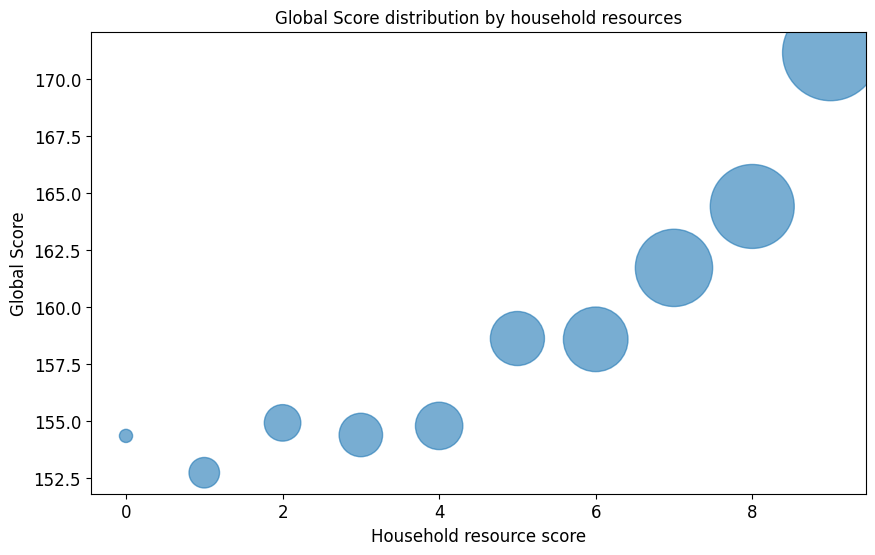

In [ ]:
resource_cols = [
    'TV',
    'COMPUTER',
    'WASHING_MCH',
    'MIC_OVEN',
    'CAR',
    'DVD',
    'PHONE',
    'MOBILE',
    'INTERNET'
]
le = LabelEncoder()
for cols in resource_cols:
  df[cols] = le.fit_transform(df[cols].astype(str))

df['RESOURCE_SCORE'] = df[resource_cols].sum(axis=1)
#print(df[resource_cols+ ['RESOURCE_SCORE']].head())

resource_details = df.groupby('RESOURCE_SCORE').agg(avg_gsc=('G_SC', 'mean'),count=('G_SC','size')).reset_index()
plt.figure(figsize=(10,6))
plt.scatter(resource_details['RESOURCE_SCORE'],resource_details['avg_gsc'],s=resource_details['count']*1.5,alpha=0.6)
plt.title('Global Score distribution by household resources',fontsize=12,fontstyle='normal')
plt.xlabel("Household resource score",fontsize=12,fontstyle='normal')
plt.ylabel("Global Score",fontsize=12,fontstyle='normal')
plt.xticks(fontsize=12,fontstyle='normal')
plt.yticks(fontsize=12,fontstyle='normal')
plt.show()

##**How does school nature and school type contribute to the academic performance?**

In [ ]:
import plotly.express as px
sunburst_df =(df.groupby(['SCHOOL_NAT','SCHOOL_TYPE'])['G_SC'].mean().reset_index())
sunburst_df.rename(columns={'G_SC':'AVG_GSC'},inplace = True)
fig=px.sunburst(sunburst_df,path=['SCHOOL_NAT','SCHOOL_TYPE'],values='AVG_GSC',color='AVG_GSC',color_continuous_scale='Purples')
fig.update_traces(textfont_size=12)
fig.update_layout(font=dict(size=12))
fig.show()

##**Average School performance**

In [ ]:
df['S11_AVG'] = (
    df['MAT_S11'] +
    df['CR_S11'] +
    df['CC_S11'] +
    df['BIO_S11'] +
    df['ENG_S11']
) / 5

##**Average University Performance**

In [ ]:
df['PRO_AVG'] = (
    df['QR_PRO'] +
    df['CR_PRO'] +
    df['CC_PRO'] +
    df['ENG_PRO'] +
    df['WC_PRO'] +
    df['FEP_PRO']
) / 6

##**Academic Growth**

In [ ]:
df['ACADEMIC_GROWTH'] = (df['PRO_AVG']-df['S11_AVG'])

##**Parental Education Index**

In [ ]:
#print(df['EDU_FATHER'].value_counts().index.tolist())
education_mapping = {
    'Ninguno': 0,
    'Incomplete primary ': 1,
    'Complete primary ': 2,
    'Incomplete Secundary': 3,
    'Complete Secundary': 4,
    'Incomplete technical or technological': 5,
    'Complete technique or technology': 6,
    'Incomplete Professional Education': 7,
    'Complete professional education': 8,
    'Postgraduate education': 9,
    'Not sure': 0,
    0:0
}

df['EDU_FATHER_ENC'] = df['EDU_FATHER'].map(education_mapping)
df['EDU_MOTHER_ENC'] = df['EDU_MOTHER'].map(education_mapping)

df['PARENT_EDU_INDEX'] = (
    df['EDU_FATHER_ENC'] +
    df['EDU_MOTHER_ENC']
) / 2


##**Family Education Gap**

In [ ]:
df['PARENT_EDU_GAP'] = abs(
    df['EDU_FATHER_ENC'] -
    df['EDU_MOTHER_ENC']
)

##**Parental occupation Index**

In [ ]:
#print(df['OCC_FATHER'].value_counts().index.tolist())
occupation_mapping = {
    'Home':0,
    'Other occupation':1,
    'Operator': 2,
    'Auxiliary or Administrative': 3,
    'Independent': 4,
    'Small entrepreneur ': 5,
    'Technical or professional level employee': 6,
    'Independent professional': 7,
    'Entrepreneur ': 8,
    'Executive': 9,
    'Retired': 10,
    0:0
}

df['OCC_FATHER_ENC'] = df['OCC_FATHER'].map(occupation_mapping)
df['OCC_MOTHER_ENC'] = df['OCC_MOTHER'].map(occupation_mapping)
df['PARENT_OCC_INDEX']=(df['OCC_FATHER_ENC']+df['OCC_MOTHER_ENC'])/2

##**Socioeconomic ('Parent education','Parent Occupation','Household resources') influence on students**


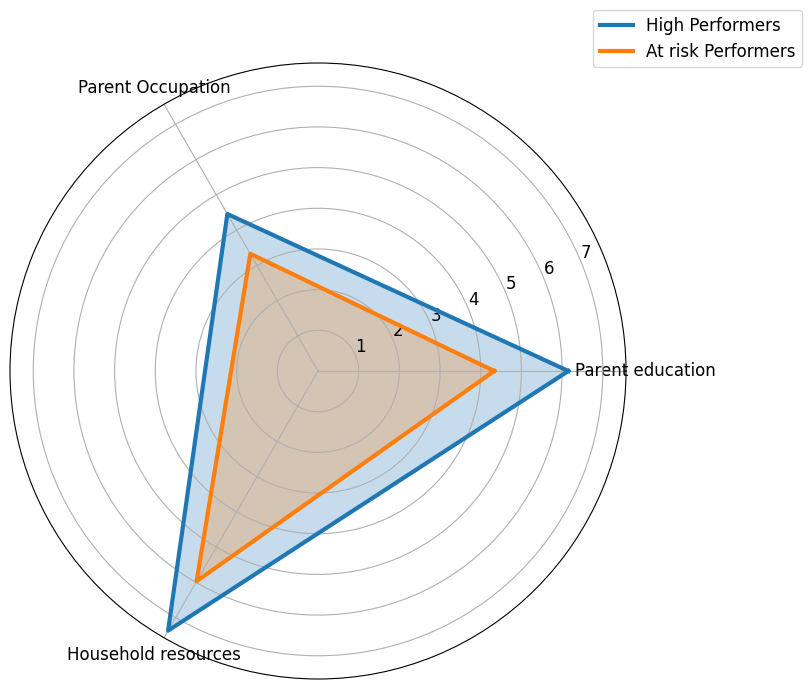

In [ ]:
high_performers=df[df['G_SC']>df['G_SC'].quantile(0.75)]
low_performers=df[df['G_SC']<df['G_SC'].quantile(0.25)]

factors= ['PARENT_EDU_INDEX','PARENT_OCC_INDEX','RESOURCE_SCORE']
mean_high_performers=high_performers[factors].mean().values.tolist()
mean_low_performers=low_performers[factors].mean().values.tolist()

mean_high_performers+=mean_high_performers[:1]
mean_low_performers+=mean_low_performers[:1]

angle=np.linspace(0,2*np.pi,len(factors),endpoint=False).tolist()
angle+=angle[:1]

plt.figure(figsize=(8,8))
x=plt.subplot(111,polar=True)

x.plot(angle,mean_high_performers,linewidth=3,label='High Performers')
x.fill(angle,mean_high_performers,alpha=0.25)
x.plot(angle,mean_low_performers,linewidth=3,label='At risk Performers')
x.fill(angle,mean_low_performers,alpha=0.25)

x.set_xticks(angle[:-1])
x.set_xticklabels(['Parent education','Parent Occupation','Household resources'],fontsize=12)
x.tick_params(axis='y',labelsize=12)
#plt.title('Socioeconomic influence on students',fontsize=12)
plt.legend(loc='upper right',bbox_to_anchor=(1.3,1.1),fontsize=12)
plt.show()

#**R2 of G_SC explained by the 6 PRO module scores (data leakage)**

In [ ]:
leak_check_cols = ['QR_PRO', 'CR_PRO', 'CC_PRO', 'ENG_PRO', 'WC_PRO', 'FEP_PRO']
leak_X = df[leak_check_cols].values
leak_y = df['G_SC'].values
leak_model = LinearRegression().fit(leak_X, leak_y)
leak_r2 = r2_score(leak_y, leak_model.predict(leak_X))
print(f"R2 of G_SC explained by the 6 PRO module scores alone: {leak_r2:.3f}")

R2 of G_SC explained by the 6 PRO module scores alone: 0.946


In [ ]:
data_copy=df.copy()
data_copy.drop(columns=['SCHOOL_NAME','UNIVERSITY','COD_S11','Cod_SPro','EDU_FATHER','EDU_MOTHER', 'PERCENTILE','2ND_DECILE','QUARTILE','QR_PRO','CR_PRO','CC_PRO','ENG_PRO','WC_PRO','FEP_PRO','PRO_AVG','ACADEMIC_GROWTH'],inplace=True)

##**Label encoding**

In [ ]:
binary_columns = ['GENDER','INTERNET','TV','COMPUTER','WASHING_MCH','MIC_OVEN','CAR','DVD','FRESH','PHONE','MOBILE','SCHOOL_NAT']
le = LabelEncoder()
for cols in binary_columns:
  data_copy[cols] = le.fit_transform(data_copy[cols].astype(str))

#print(data_copy[binary_columns].head())

##**One hot encoding**

In [ ]:
data_copy = pd.get_dummies(
    data_copy,
    columns=['SCHOOL_TYPE','ACADEMIC_PROGRAM'],
    drop_first=True
)

##**Ordinal encoding**

In [ ]:
#print(data_copy['STRATUM'].value_counts().index.tolist())
stratum_mapping = {
    'Stratum 3':3,
    'Stratum 2':2,
    'Stratum 1':1,
    'Stratum 4':4,
    'Stratum 5':5,
    'Stratum 6':6,
    0:0
}

data_copy['STRATUM_ENC'] = data_copy['STRATUM'].map(stratum_mapping)

#print(data_copy['SISBEN'].value_counts().index.tolist())
sisben_mapping = {
    'It is not classified by the SISBEN':5,
    'Level 2':2,
    'Level 1':1,
    'Level 3':3,
    'Esta clasificada en otro Level del SISBEN':4,
    0:0
}

data_copy['SISBEN_ENC'] = data_copy['SISBEN'].map(sisben_mapping)

#print(data_copy['REVENUE'].value_counts().index.tolist())
revenue_mapping = {
    'Between 1 and less than 2 LMMW':2,
    'Between 2 and less than 3 LMMW':3,
    'Between 3 and less than 5 LMMW':4,
    'less than 1 LMMW':1,
    'Between 5 and less than 7 LMMW':5,
    '10 or more LMMW':7,
    'Between 7 and less than 10 LMMW':6,
    0:0
}

data_copy['REVENUE_ENC'] = data_copy['REVENUE'].map(revenue_mapping)

#print(data_copy['JOB'].value_counts().index.tolist())
job_mapping = {
    'No':0,
    'Yes, less than 20 hours per week':1,
    'Yes, 20 hours or more per week':2,
    0:0
}

data_copy['JOB_ENC'] = data_copy['JOB'].map(job_mapping)

#print(data_copy['PEOPLE_HOUSE'].value_counts().index.tolist())
people_mapping = {
    'Four':4,
    'Five':5,
    'Three':3,
    'Six':6,
    'Two':2,
    'Seven':7,
    'Eight':8,
    'Nueve':9,
    'Ten':10,
    'Twelve or more':12,
    'Once':1,
    'One':1,
    0:0
}

data_copy['PEOPLE_HOUSE_ENC'] = data_copy['PEOPLE_HOUSE'].map(people_mapping)

data_copy.drop(columns=['STRATUM','SISBEN','PEOPLE_HOUSE','REVENUE','JOB','OCC_FATHER','OCC_MOTHER'],inplace=True)

#**6. Model Implementation**

##**Define features and target**

In [ ]:
X = data_copy.drop('G_SC', axis=1).copy()
y = data_copy['G_SC'].copy()
print("Feature Shape: ",X.shape)

Feature Shape:  (12411, 56)


##**Train-Test Split**

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Training data shape: ",X_train.shape)
print("Testing data shape: ",X_test.shape)

Training data shape:  (9928, 56)
Testing data shape:  (2483, 56)


###**Standardatization for linear regression only**

In [ ]:
s=StandardScaler()
X_train_scaled=s.fit_transform(X_train)
X_test_scaled=s.transform(X_test)

###**Define Model**

In [ ]:
lr=LinearRegression()
dt=DecisionTreeRegressor(random_state=42,max_depth=5,min_samples_split=10,min_samples_leaf=5)
rf=RandomForestRegressor(max_depth=6,random_state=42,min_samples_leaf=15)
xgb=XGBRegressor(learning_rate=0.03,max_depth=4,reg_alpha=0.5,random_state=42)
models={'Linear regression':lr,'Decision tree':dt,'Random forest':rf,'XGBoost':xgb}

###**Train, evaluate and compare model performance**

In [ ]:
def ml_models(model,X_train,X_test,y_train,y_test,name):
  model.fit(X_train,y_train)
  train_prediction = model.predict(X_train)
  test_prediction=model.predict(X_test)
  #Evaluation
  train_mae=mean_absolute_error(y_train,train_prediction)
  test_mae=mean_absolute_error(y_test,test_prediction)
  train_rmse=np.sqrt(mean_squared_error(y_train,train_prediction))
  test_rmse=np.sqrt(mean_squared_error(y_test,test_prediction))
  train_r2=r2_score(y_train,train_prediction)
  test_r2=r2_score(y_test,test_prediction)

  return{"Model":name,
         "MAE(Train)":train_mae,
         "MAE(Test)":test_mae,
         "RMSE(train)":train_rmse,
         "RMSE(test)":test_rmse,
         "R2(train)":train_r2,
         "R2(test)":test_r2,
         "R2 Gap":train_r2-test_r2},train_prediction,test_prediction

result_rows=[]
predictions={}
for name,model in models.items():
  if name=='Linear regression':
    result,train_prediction,test_prediction=ml_models(model,X_train_scaled,X_test_scaled,y_train,y_test,name)
    result_rows.append(result)
    predictions[name]={"train":train_prediction,"test":test_prediction}
  else:
    result,train_prediction,test_prediction=ml_models(model,X_train,X_test,y_train,y_test,name)
    result_rows.append(result)
    predictions[name]={"train":train_prediction,"test":test_prediction}
evaluation_results=pd.DataFrame(result_rows)
display(evaluation_results.sort_values(["R2 Gap"]).round(2))


,Model,MAE(Train),MAE(Test),RMSE(train),RMSE(test),R2(train),R2(test),R2 Gap
0,Linear regression,10.98,10.94,14.27,14.31,0.62,0.61,0.01
3,XGBoost,10.72,10.90,13.95,14.31,0.64,0.61,0.03
1,Decision tree,10.87,11.12,14.19,14.56,0.62,0.59,0.03
2,Random forest,10.57,10.93,13.80,14.36,0.65,0.61,0.04


###**Actual Value vs Predicted Value**

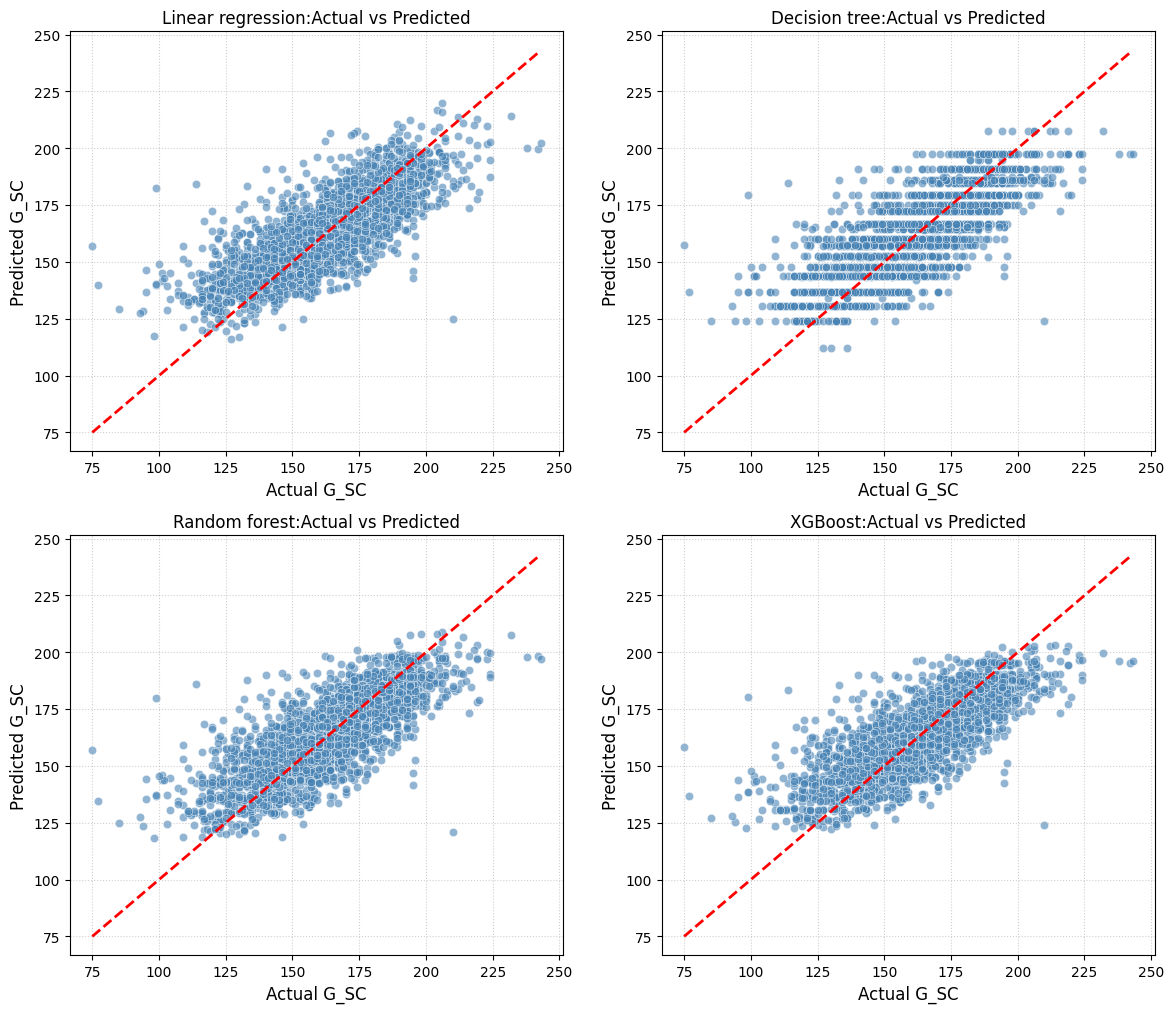

In [ ]:
fig,axes=plt.subplots(2,2,figsize=(14,12))
axes=axes.flatten()
for idx, name in enumerate(predictions.keys()):
  ax=axes[idx]
  y_pred=predictions[name]["test"]
  sns.scatterplot(x=y_test,y=y_pred,alpha=0.6,ax=ax,color='steelblue')
  low,high=y_test.min(),y_test.max()
  ax.plot([low,high],[low,high],'r--',linewidth=2)
  ax.set_title(f"{name}:Actual vs Predicted",fontsize=12)
  ax.set_xlabel("Actual G_SC",fontsize=12)
  ax.set_ylabel("Predicted G_SC",fontsize=12)
  ax.grid(True,linestyle=':',alpha=0.6)
for i in range(len(predictions),len(axes)):
  fig.delaxes(axes[i])
  plt.tight_layout()
  plt.show()

###**Feature Importance**

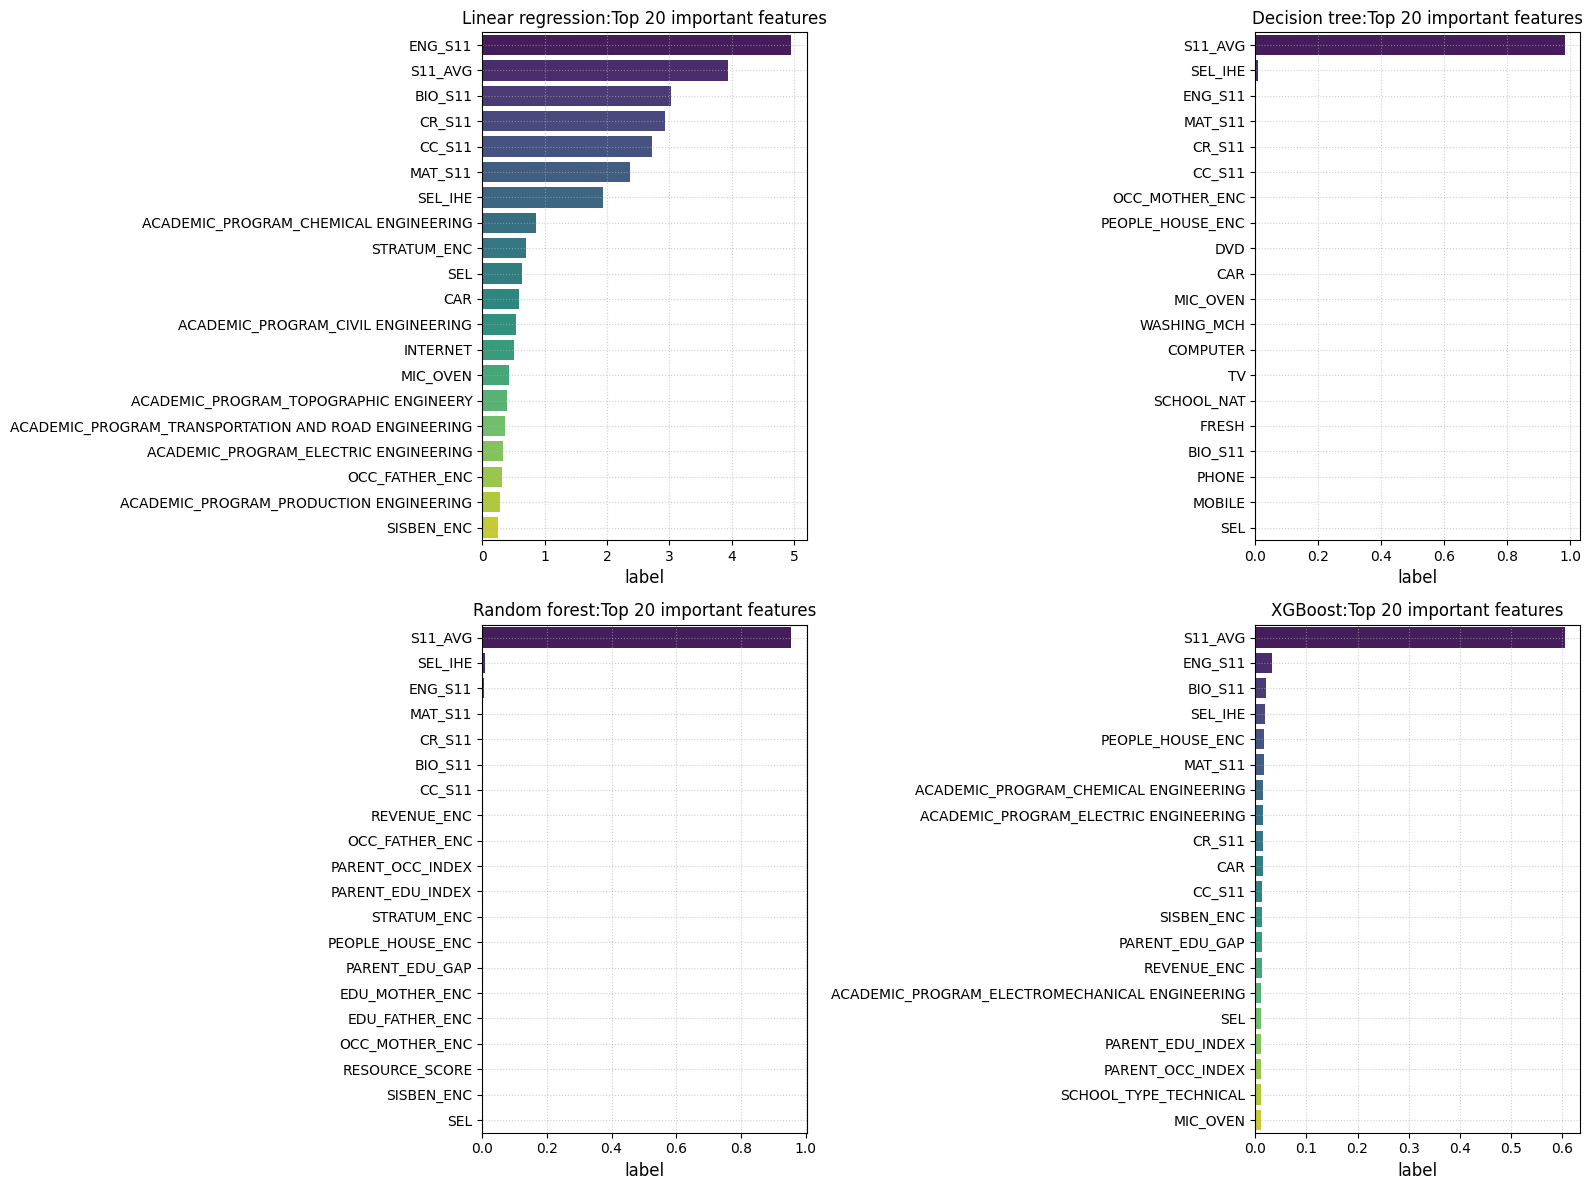

In [ ]:
fig,axes=plt.subplots(2,2,figsize=(16,12))
axes=axes.flatten()
features=X_train.columns
models_list=[('Linear regression',lr,'coefficients'),('Decision tree',dt,'importance'),('Random forest',rf,'importance'),('XGBoost',xgb,'importance')]
for idx, (name,model,coef) in enumerate(models_list):
  ax=axes[idx]
  if coef=='coefficients':
    values=np.abs(model.coef_)
    label='Absolute coefficient'
  else:
    values=model.feature_importances_
    label='Feature importance'
  df_imp=pd.DataFrame({'Feature':features,'Value':values})
  df_imp=df_imp.sort_values(by='Value',ascending=False).head(20)
  sns.barplot(data=df_imp,x='Value',y='Feature',ax=ax,hue='Feature',legend=False,palette='viridis')
  ax.set_title(f"{name}:Top 20 important features",fontsize=12)
  ax.set_xlabel("label",fontsize=12)
  ax.set_ylabel("",fontsize=12)
  ax.grid(True,linestyle=':',alpha=0.6)
plt.tight_layout()
plt.show()

#**7. SHAP Analysis for XGBoost**

In [ ]:
explainer= shap.TreeExplainer(xgb)
shap_values=explainer(X_test)

##**SHAP Summary Plot**

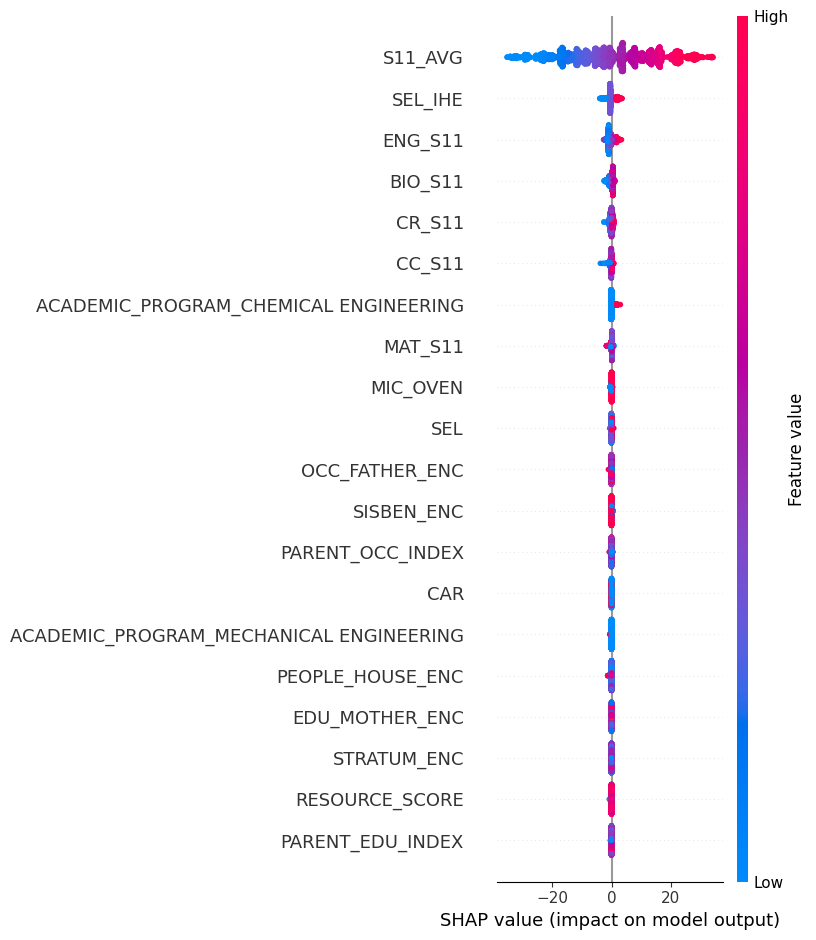

In [ ]:
shap.summary_plot(shap_values,X_test)

##**SHAP Bar Plot**

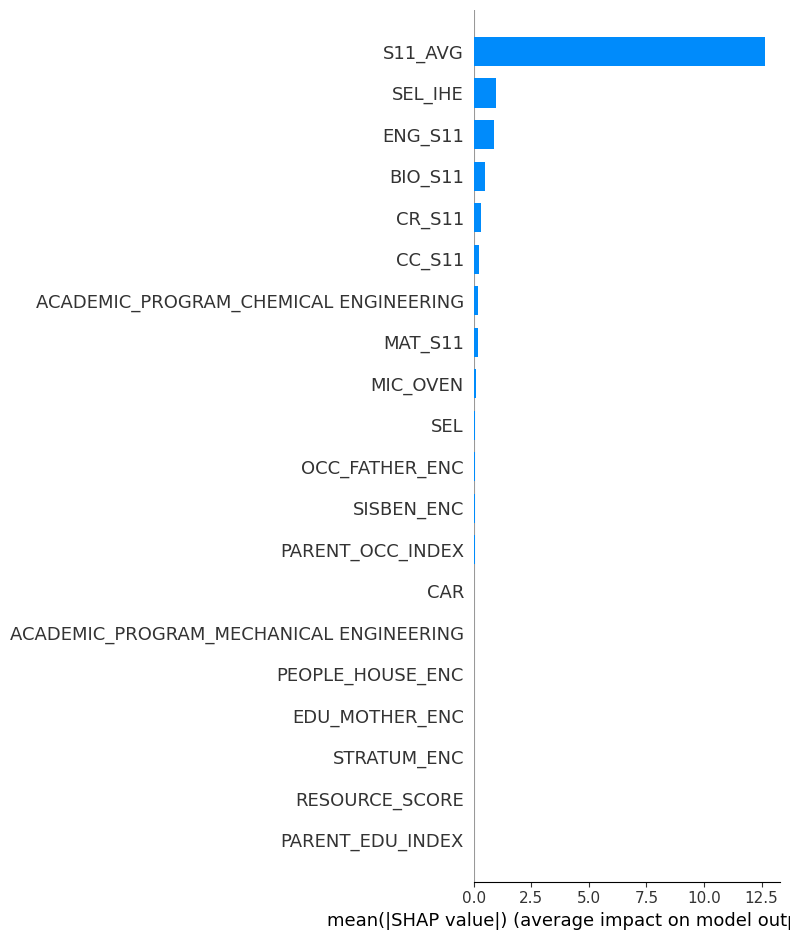

In [ ]:
shap.summary_plot(shap_values,X_test,plot_type='bar')

##**SHAP Waterfall Plot**

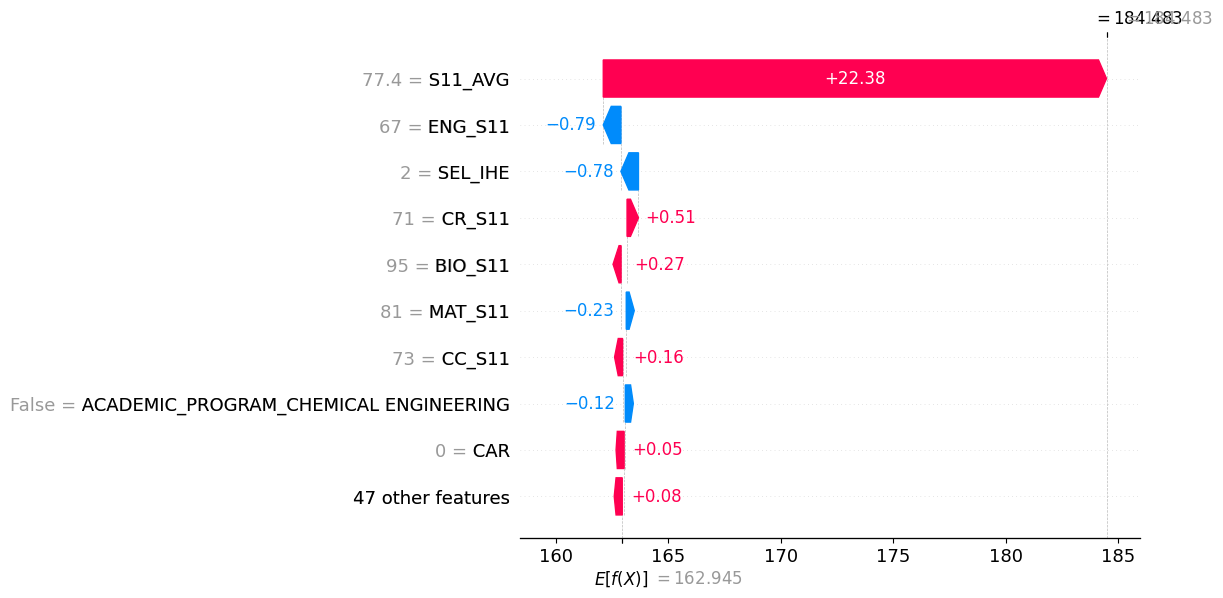

In [ ]:
shap.plots.waterfall(shap_values[0])

##**SHAP Beeswarm Plot**

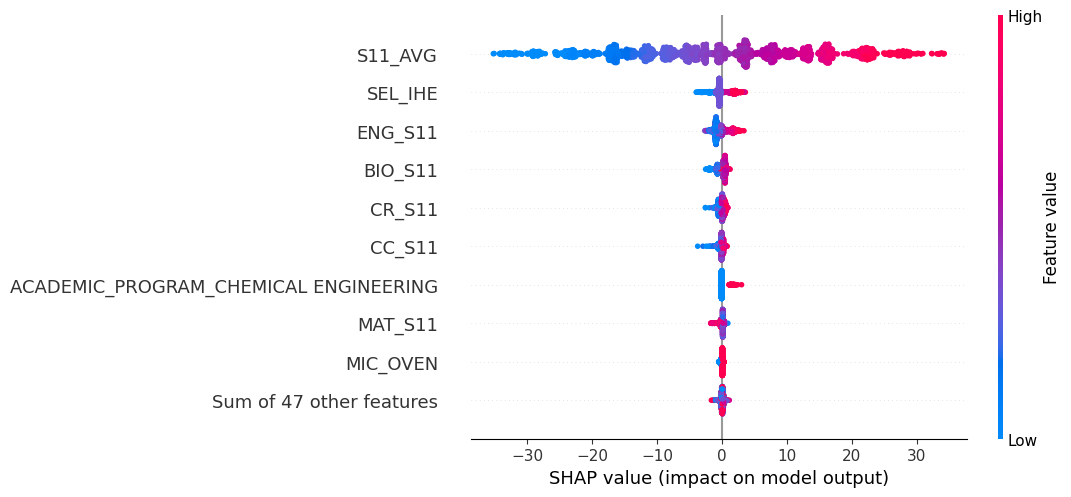

In [ ]:
shap.plots.beeswarm(shap_values)

##**SHAP Dependence Plot**

Top feature by mean of absolute SHAP value:  S11_AVG


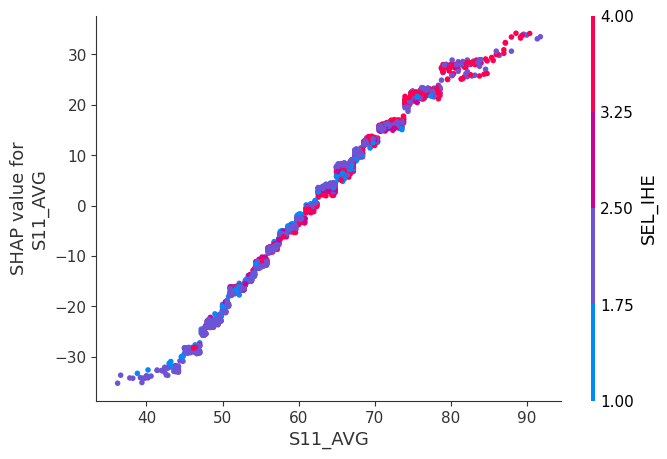

In [ ]:
mean_shap_value=np.abs(shap_values.values).mean(axis=0)
imp_feature=X_test.columns[np.argmax(mean_shap_value)]
print("Top feature by mean of absolute SHAP value: ", imp_feature)

shap.dependence_plot(imp_feature,shap_values.values,X_test)

##**SHAP Force Plot**

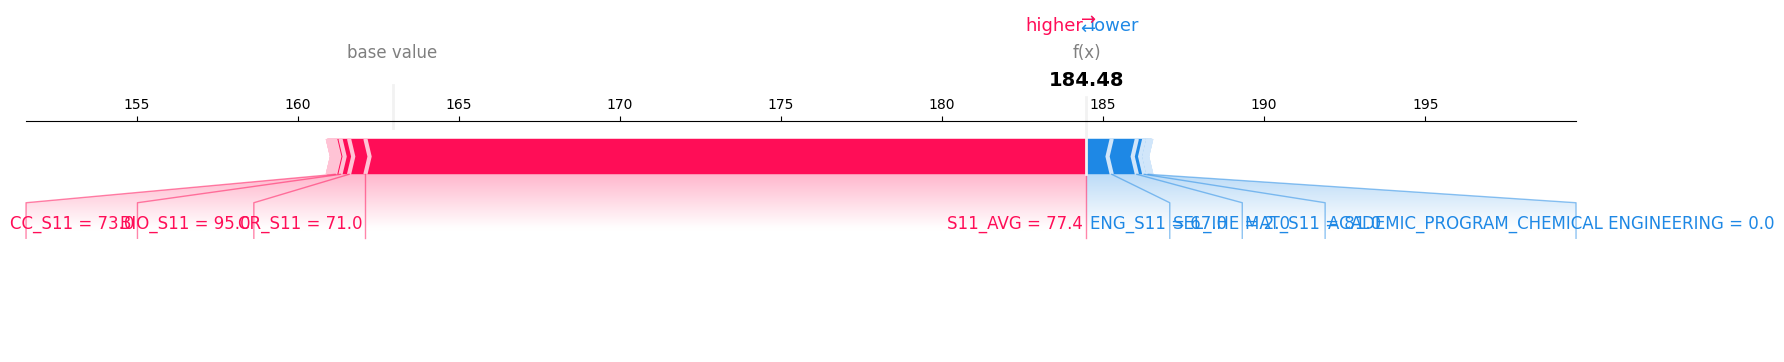

In [ ]:
shap.force_plot(explainer.expected_value,shap_values.values[0],X_test.iloc[0],matplotlib=True)
plt.show()

#**Export Dashboard data**

In [ ]:
dashboard_data=df.copy()
dashboard_data.to_csv('student_dashboard_data.csv',index=False)
#print("CSV created successfully")

# Evaluation results
evaluation_results.round(4).to_csv(
    "model_evaluation_results.csv",
    index=False
)


# Actual VS Predicted
prediction_rows = []

for name, pred in predictions.items():

    temp = pd.DataFrame({
        "Student_Index": y_test.index,
        "Model": name,
        "Actual_G_SC": y_test.values,
        "Predicted_G_SC": pred["test"]
    })

    temp["Error"] = (
        temp["Actual_G_SC"] -
        temp["Predicted_G_SC"]
    )

    temp["Absolute_Error"] = temp["Error"].abs()

    prediction_rows.append(temp)

prediction_dashboard = pd.concat(
    prediction_rows,
    ignore_index=True
)

prediction_dashboard.to_csv(
    "model_predictions.csv",
    index=False
)


# Feature Importance
feature_names = X_train.columns

importance_rows = []

for name, model, importance_type in [
    ("Linear regression", lr, "coefficients"),
    ("Decision tree", dt, "importance"),
    ("Random forest", rf, "importance"),
    ("XGBoost", xgb, "importance")
]:

    if importance_type == "coefficients":
        values = np.abs(model.coef_)
        measure = "Absolute coefficient"
    else:
        values = model.feature_importances_
        measure = "Feature importance"

    temp = pd.DataFrame({
        "Model": name,
        "Feature": feature_names,
        "Importance": values,
        "Importance_Type": measure
    })

    importance_rows.append(temp)

feature_importance_dashboard = pd.concat(
    importance_rows,
    ignore_index=True
)

feature_importance_dashboard.to_csv(
    "feature_importance.csv",
    index=False
)


# SHAP importance
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance_dashboard = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_dashboard = (
    shap_importance_dashboard
    .sort_values(
        "Mean_Absolute_SHAP",
        ascending=False
    )
)

shap_importance_dashboard.to_csv(
    "shap_feature_importance.csv",
    index=False
)


print("All dashboard files created successfully.")

All dashboard files created successfully.
